# 04 · Limited budget - Table 11, Figs. 5-8 and Video 1

Section 3.5: the company has a limited yearly budget $B$ for interventions (Eq. 46). Three
variants of Case 1 are solved (1A: 2.625, 1B: 4.125, 1C: 5.250 kUSD/y) and then a sweep over
the budget shows how the optimal set of interventions evolves.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from coolingnet import paper_case
from coolingnet.optimization import SolverSettings
from coolingnet.reporting import figures as F
from coolingnet.reporting import paper_reference as REF
from coolingnet.reporting import tables as T
from coolingnet.workflow import PaperPipeline, PipelineConfig

RESULTS_DIR = Path("../results")
FORCE_RESOLVE = False

case = paper_case()
pipeline = PaperPipeline(case, PipelineConfig(results_dir=RESULTS_DIR, force=FORCE_RESOLVE, solver=SolverSettings(name="nlpbb", time_limit_s=900)))
sims = pipeline.run_simulations()
unlimited = pipeline.run_unlimited()
budget_cases = pipeline.run_budget_cases()
for name, s in budget_cases.items():
    print(name, s.report["termination"], f"B = {s.budget / 1e3:.3f} kUSD/y", f"objective = {s.costs['total_cost'] / 1e3:.2f} kUSD/y", f"capital = {s.costs['capital'] / 1e3:.3f} kUSD/y")

budget_1A optimal B = 2.625 kUSD/y objective = 86.93 kUSD/y capital = 2.577 kUSD/y
budget_1B optimal B = 4.125 kUSD/y objective = 85.03 kUSD/y capital = 3.766 kUSD/y
budget_1C optimal B = 5.250 kUSD/y objective = 84.77 kUSD/y capital = 4.706 kUSD/y


## Table 11 - optimization results with a finite budget

In [2]:
short = {k.replace("budget_", ""): v for k, v in budget_cases.items()}
display(T.table_budget_cases(short))
frames = {k: v.exchangers_df() for k, v in short.items()}
computed = pd.DataFrame(
    {
        **{f"Optimal flow {k} (kg/s)": f["k_kg_s"] for k, f in frames.items()},
        **{f"Valve head loss {k} (m)": f["valve_head_loss_m"] for k, f in frames.items()},
        **{f"Penalty {k} (kUSD/y)": f["penalty_USD_y"] / 1e3 for k, f in frames.items()},
    }
)
display(REF.compare(REF.TABLE11, computed).round(2))
display(T.table_costs(short).round(3))

,Optimal cooling water flow rate (kg/s) 1A/1B/1C,Valve head loss (m) 1A/1B/1C,Penalty (kUSD/y) 1A/1B/1C
Heat exchanger,,,
E-101,12.01/13.52/13.53,0.00/0.53/0.27,1.76/0.00/0.00
E-102,25.71/30.16/30.27,1.46/1.78/1.48,23.79/19.94/19.86
E-103,35.67/41.64/40.96,0.00/0.00/0.00,22.54/16.72/17.65
E-104,17.65/18.16/18.98,0.00/0.00/0.00,16.09/17.32/15.34
E-105,3.66/3.87/3.87,0.03/1.02/0.23,0.00/0.00/0.00
Total,94.70/107.35/107.62,-,64.17/53.98/52.85


,Optimal flow 1A (kg/s) [paper],Optimal flow 1A (kg/s) [this work],Optimal flow 1B (kg/s) [paper],Optimal flow 1B (kg/s) [this work],Optimal flow 1C (kg/s) [paper],Optimal flow 1C (kg/s) [this work],Valve head loss 1A (m) [paper],Valve head loss 1A (m) [this work],Valve head loss 1B (m) [paper],Valve head loss 1B (m) [this work],Valve head loss 1C (m) [paper],Valve head loss 1C (m) [this work],Penalty 1A (kUSD/y) [paper],Penalty 1A (kUSD/y) [this work],Penalty 1B (kUSD/y) [paper],Penalty 1B (kUSD/y) [this work],Penalty 1C (kUSD/y) [paper],Penalty 1C (kUSD/y) [this work]
Heat exchanger,,,,,,,,,,,,,,,,,,
E-101,12.01,12.01,13.51,13.52,13.53,13.53,0.00,0.00,0.51,0.53,0.27,0.27,1.76,1.76,0.00,0.00,0.00,0.00
E-102,25.71,25.71,30.02,30.16,30.27,30.27,1.45,1.46,1.81,1.78,1.48,1.48,23.79,23.79,20.06,19.94,19.86,19.86
E-103,35.67,35.67,41.56,41.64,40.96,40.96,0.00,0.00,0.00,0.00,0.00,0.00,22.54,22.54,16.77,16.72,17.65,17.65
E-104,17.65,17.65,18.12,18.16,18.98,18.98,0.00,0.00,0.00,0.00,0.00,0.00,16.09,16.09,17.37,17.32,15.34,15.34
E-105,3.66,3.66,3.86,3.87,3.87,3.87,0.03,0.03,1.62,1.02,0.23,0.23,0.00,0.00,0.00,0.00,0.00,0.00


,Pipe (kUSD/y),Pump (kUSD/y),Operating (kUSD/y),Penalty (kUSD/y),Objective (kUSD/y),Budget (kUSD/y),Pump option,Pipes changed,Solver status
Run,,,,,,,,,
1A,2.577,0.000,20.191,64.166,86.934,2.625,1,2,optimal
1B,0.349,3.417,27.282,53.983,85.030,4.125,4,2,optimal
1C,1.288,3.417,27.212,52.848,84.765,5.250,4,1,optimal


## Figs. 5 and 6 - interventions of Cases 1A and 1C

Case 1A substitutes two pipes and keeps the pump; Case 1B buys the most powerful pump and
changes no pipe; Case 1C combines the new pump with one pipe substitution.

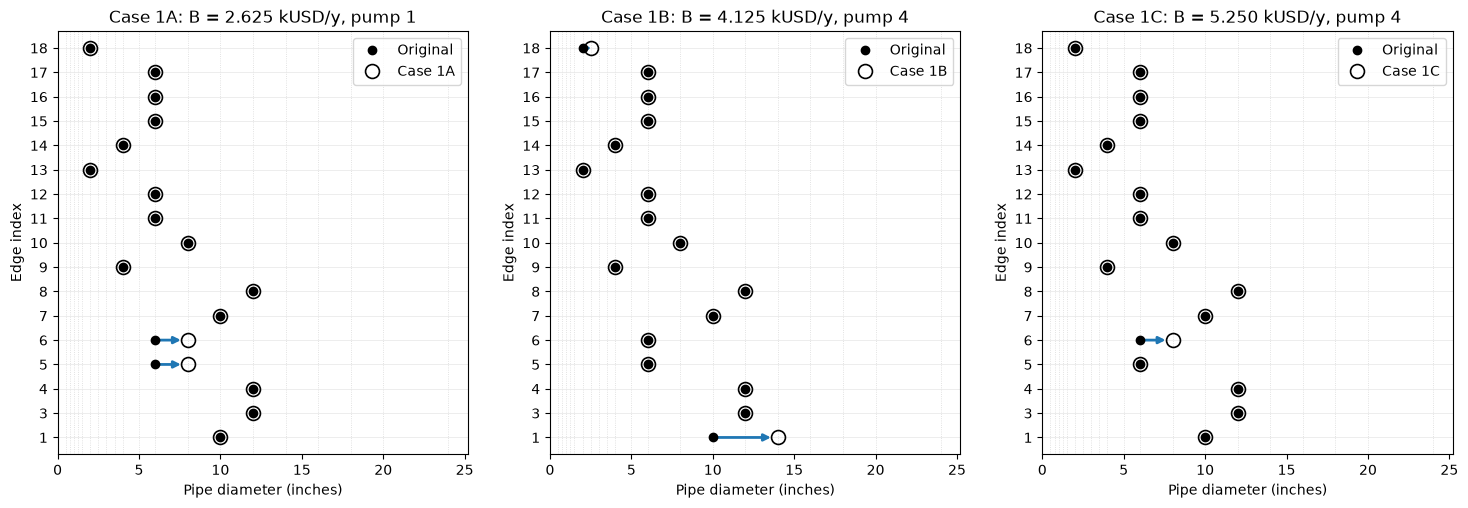

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, name in zip(axes, short, strict=True):
    F.plot_diameter_dotchart(case, short[name], ax=ax, label=f"Case {name}", title=f"Case {name}: B = {short[name].budget / 1e3:.3f} kUSD/y, pump {short[name].pump_options()['2']}")
fig.savefig("../figures/fig05_06_diameters_budget_cases.png", dpi=150, bbox_inches="tight")

## Figs. 7 and 8 - budget sweep

Beyond ~3 kUSD/y it becomes more interesting to buy the new pump and give up the additional
pipe capacity (sudden drop of the penalty). The hatched region in Fig. 8 is above the budget
line (infeasible capital cost).

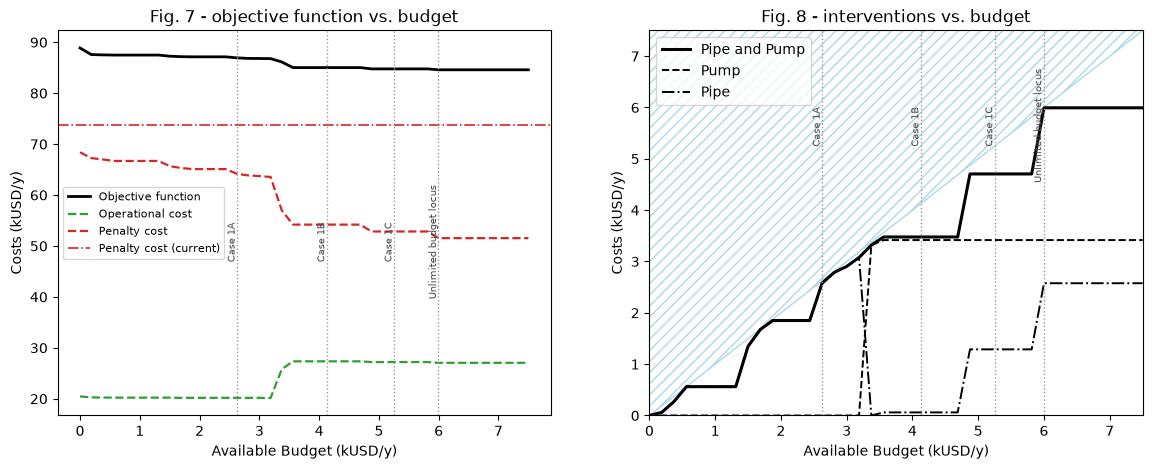

In [4]:
sweep = pipeline.run_budget_sweep()
markers = {f"Case {k}": v for k, v in case.scenarios.budget_cases.items()}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
F.plot_budget_costs(sweep, ax=axes[0], current_penalty=sims["current"].costs["cpen"], unlimited=unlimited["case1"], markers=markers, title="Fig. 7 - objective function vs. budget")
F.plot_budget_interventions(sweep, ax=axes[1], unlimited=unlimited["case1"], markers=markers, title="Fig. 8 - interventions vs. budget")
fig.savefig("../figures/fig07_08_budget_sweep.png", dpi=150, bbox_inches="tight")

In [5]:
pd.DataFrame(
    {
        "budget (kUSD/y)": [s.budget / 1e3 for s in sweep],
        "pipe (kUSD/y)": [s.costs["cpipe"] / 1e3 for s in sweep],
        "pump (kUSD/y)": [s.costs["cpump"] / 1e3 for s in sweep],
        "operating (kUSD/y)": [s.costs["cope"] / 1e3 for s in sweep],
        "penalty (kUSD/y)": [s.costs["cpen"] / 1e3 for s in sweep],
        "objective (kUSD/y)": [s.costs["total_cost"] / 1e3 for s in sweep],
        "pump option": ["/".join(s.pump_options().values()) for s in sweep],
        "pipes changed": [", ".join(f"{e['id']}:{e['diameter_in']:g}in" for e in s.edges if e["kind"] == "pipe" and e.get("changed")) for s in sweep],
        "status": [s.report["termination"] for s in sweep],
    }
).round(3)

,budget (kUSD/y),pipe (kUSD/y),pump (kUSD/y),operating (kUSD/y),penalty (kUSD/y),objective (kUSD/y),pump option,pipes changed,status
0,0.000,0.000,0.000,20.473,68.396,88.869,1,,optimal
1,0.188,0.060,0.000,20.267,67.255,87.582,1,13:2.5in,optimal
2,0.375,0.273,0.000,20.247,66.997,87.517,1,"9:6in, 18:2.5in",optimal
3,0.562,0.562,0.000,20.226,66.693,87.481,1,"1:14in, 9:6in, 18:2.5in",optimal
4,0.750,0.562,0.000,20.226,66.693,87.481,1,"1:14in, 9:6in, 18:2.5in",optimal
5,0.938,0.562,0.000,20.226,66.693,87.481,1,"1:14in, 13:2.5in, 14:6in",optimal
6,1.125,0.562,0.000,20.226,66.693,87.481,1,"1:14in, 13:2.5in, 14:6in",optimal
7,1.312,0.562,0.000,20.226,66.693,87.481,1,"1:14in, 13:2.5in, 14:6in",optimal
8,1.500,1.349,0.000,20.232,65.681,87.262,1,"6:8in, 18:2.5in",optimal
9,1.688,1.676,0.000,20.182,65.311,87.169,1,"6:8in, 9:5in, 14:5in, 18:2.5in",optimal


## Video 1 - evolution of the solution with the budget limit

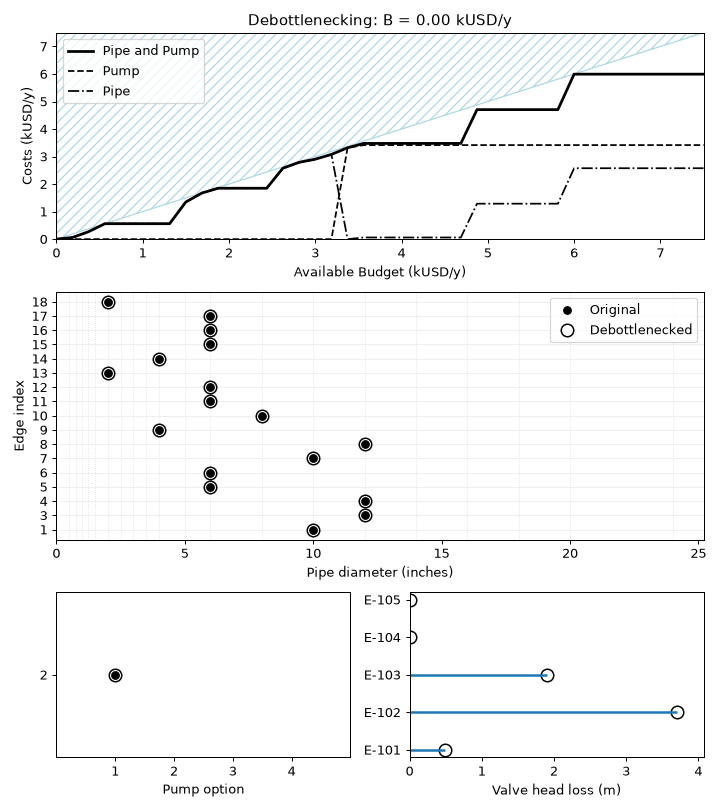

In [6]:
gif = F.save_budget_animation(case, sweep, "../figures/video01_budget_animation.gif", fps=1.0)
display(Image(filename=str(gif)))